In [ ]:
# ==============================================================================
# SCRIPT 5 - ECONOMETRIC ANALYSIS (RESIDENTIAL DiD + COMMERCIAL ANTICIPATION)
# ENVIRONMENT SETUP
# ==============================================================================
%pip install pandas numpy statsmodels geopandas pyarrow matplotlib -q

import os
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
np.random.seed(42)
print("Environment ready.")

Environment ready.


In [ ]:
# ==============================================================================
# LOCATE THE PROJECT FOLDER
# ==============================================================================
# Finds the cloned repository (the folder that contains 03_scripts).
# Works locally, in Colab and elsewhere. Set the PROJECT_ROOT environment variable to override.
import os
from pathlib import Path

def find_project_root():
    if os.environ.get("PROJECT_ROOT"):
        return Path(os.environ["PROJECT_ROOT"])
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "03_scripts").is_dir():
            return folder
    colab_clone = Path("/content/rail-station-property-values")
    if colab_clone.is_dir():
        return colab_clone
    raise FileNotFoundError("Project folder not found. Run the notebook from inside the cloned repository, or set PROJECT_ROOT.")

PROJECT_ROOT = str(find_project_root())
print(f"Project folder: {PROJECT_ROOT}")

In [ ]:
# ==============================================================================
# LOAD RESIDENTIAL DATA & CONSTRUCT DESIGN VARIABLES
# ------------------------------------------------------------------------------
# Design (sized to observed cell counts):
#   * Treated stations: Marsh Barton (opened 2023-07-04), Okehampton (reopened 2021-11-20)
#   * Two "clocks": Urban (Marsh Barton group) and Rural (Okehampton group)
#   * Catchment = 0-1600m (per the 4-band isochrone design); 1600m+ is OUT of catchment
#   * Primary causal contrast: Near (0-800m) vs Baseline zone (1200-1600m);
#     the 800-1200m "spillover" band is excluded but
#     retained for the 4-band descriptive hedonic.
#   * Post = Operational epoch; primary DiD uses Baseline vs Operational only.
# ==============================================================================
BASE_DIR = PROJECT_ROOT
RES_PATH = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_residential.parquet')
FIG_DIR  = os.path.join(BASE_DIR, '04_results/figures')
TAB_DIR  = os.path.join(BASE_DIR, '04_results/tables')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

res = pd.read_parquet(RES_PATH)
res['Distance_Band'] = res['Distance_Band'].astype(str)
res['Date_of_Transfer'] = pd.to_datetime(res['Date_of_Transfer'])

# --- Treatment & group mapping (strip the " Rail Station" suffix for matching) ---
res['Station'] = res['CommonName'].str.replace(' Rail Station', '', regex=False).str.strip()

TREATED_STATIONS = ['Marsh Barton', 'Okehampton']
RURAL_GROUP = ['Okehampton', 'Crediton', 'Honiton', 'Barnstaple']
URBAN_GROUP = ['Marsh Barton', 'Exeter St Thomas', 'Digby & Sowton', 'Pinhoe',
               'Devonport', 'St Budeaux Victoria Road', 'Torre', 'Paignton']
OPENING = {'Okehampton': pd.Timestamp('2021-11-20'), 'Marsh Barton': pd.Timestamp('2023-07-04')}

res['Treated'] = res['Station'].isin(TREATED_STATIONS).astype(int)
res['Group'] = np.where(res['Station'].isin(RURAL_GROUP), 'Rural',
               np.where(res['Station'].isin(URBAN_GROUP), 'Urban', 'Unassigned'))

# --- Spatial / temporal design flags ---
res['In_Catchment'] = (res['Distance_Band'] != '1600m+')
res['Near'] = res['Distance_Band'].isin(['0-400m', '400-800m']).astype(int)   # 0-800m
res['Ref']  = (res['Distance_Band'] == '1200-1600m')                          # baseline zone
res['Post'] = (res['Epoch'] == 'Operational').astype(int)

# --- Exact-date epoch-aware service frequency (zero before a treated station opens) ---
def epoch_frequency(row):
    if row['Station'] in OPENING and row['Date_of_Transfer'] < OPENING[row['Station']]:
        return 0.0
    return float(row['Service_Intensity_SEII'])
res['Service_Intensity_Epoch'] = res.apply(epoch_frequency, axis=1)

print("Rows:", len(res))
print("\nGroup x Treated:")
print(pd.crosstab(res['Group'], res['Treated']))
print("\nUnassigned stations (should be none):",
      res.loc[res['Group'] == 'Unassigned', 'Station'].unique())

Rows: 31883

Group x Treated:
Treated      0     1
Group               
Rural     4759  1243
Urban    24388  1493

Unassigned stations (should be none): []


In [ ]:
# ==============================================================================
# TABLE 1 - PRE-INTERVENTION BALANCE (Treatment vs Control, Baseline epoch only)
# ==============================================================================
def balance_table(df, label):
    base = df[(df['Epoch'] == 'Baseline') & (df['In_Catchment'])]
    cols = {'Price_Normalised': 'Mean HPI-adjusted price (GBP)',
            'Total_Floor_Area': 'Mean floor area (sqm)',
            'IMD_Decile': 'Mean IMD decile',
            'walk_dist_m': 'Mean walk dist (m)'}
    rows = []
    for c, name in cols.items():
        t = base.loc[base['Treated'] == 1, c]
        k = base.loc[base['Treated'] == 0, c]
        # standardised difference
        pooled_sd = np.sqrt((t.var() + k.var()) / 2)
        std_diff = (t.mean() - k.mean()) / pooled_sd if pooled_sd > 0 else np.nan
        rows.append([name, round(t.mean(), 2), round(k.mean(), 2),
                     round(t.mean() - k.mean(), 2), round(std_diff, 3)])
    out = pd.DataFrame(rows, columns=['Variable', 'Treatment', 'Control', 'Difference', 'Std. diff'])
    print(f"\n=== Balance ({label}) | Treated N={int((base['Treated']==1).sum())}, "
          f"Control N={int((base['Treated']==0).sum())} ===")
    print(out.to_string(index=False))
    return out

bal_all   = balance_table(res, "All stations")
bal_urban = balance_table(res[res['Group'] == 'Urban'], "Urban clock")
bal_rural = balance_table(res[res['Group'] == 'Rural'], "Rural clock")
bal_all.to_csv(os.path.join(TAB_DIR, 'pre-intervention_balance_both_clocks.csv'), index=False)
bal_urban.to_csv(os.path.join(TAB_DIR, 'pre-intervention_balance_urban_clock.csv'), index=False)
bal_rural.to_csv(os.path.join(TAB_DIR, 'pre-intervention_balance_rural_clock.csv'), index=False)


=== Balance (All stations) | Treated N=168, Control N=5131 ===
                     Variable  Treatment   Control  Difference  Std. diff
Mean HPI-adjusted price (GBP)  261978.42 267859.65    -5881.23     -0.050
        Mean floor area (sqm)      96.24     97.53       -1.29     -0.022
              Mean IMD decile       5.24      4.78        0.47      0.226
           Mean walk dist (m)    1195.95   1038.05      157.90      0.466

=== Balance (Urban clock) | Treated N=47, Control N=4168 ===
                     Variable  Treatment   Control  Difference  Std. diff
Mean HPI-adjusted price (GBP)  308476.88 263225.66    45251.22      0.348
        Mean floor area (sqm)      90.02     98.40       -8.38     -0.136
              Mean IMD decile       7.98      4.59        3.39      2.058
           Mean walk dist (m)    1392.67   1046.90      345.77      1.345

=== Balance (Rural clock) | Treated N=121, Control N=963 ===
                     Variable  Treatment   Control  Difference  Std. dif

In [ ]:
# ==============================================================================
# PRIMARY RESIDENTIAL DiD (TRIPLE-DIFFERENCE)
# Dissertation cross-reference: Specification 1, section 3.7
# ------------------------------------------------------------------------------
# Log_Price ~ Treated * Near * Post + controls
#   Near = 0-800m, reference = 1200-1600m boundary zone (800-1200m excluded)
#   Sample = in-catchment, {Near or Ref}, Epoch in {Baseline, Operational}
# ==============================================================================
CONTROLS = "Log_Floor_Area + C(EPC_Rating) + IMD_Decile + C(Property_Type) + Is_New_Build"

prim = res[res['In_Catchment'] & (res['Near'] | res['Ref']) &
           res['Epoch'].isin(['Baseline', 'Operational'])].copy()
# complete cases on all model variables (defensive)
prim = prim.dropna(subset=['Log_Price', 'Log_Floor_Area', 'EPC_Rating', 'IMD_Decile',
                           'Property_Type', 'Is_New_Build', 'LSOA21CD'])
print("Primary DiD sample N =", len(prim))
print(pd.crosstab([prim['Treated'], prim['Near']], prim['Post']))

# Property type composition - Dissertation cross-reference: Appendix B, Table B.3
pt_counts = prim['Property_Type'].value_counts().sort_index().reset_index()
pt_counts.columns = ['Property_Type', 'Count']
pt_counts['Pct'] = (pt_counts['Count'] / len(prim) * 100).round(1)
print(f"\nProperty type composition of DiD analytic sample (N={len(prim):,})")
print(pt_counts.to_string(index=False))
print("Note: Detached is the reference category (alphabetical default in patsy).")

f_full = f"Log_Price ~ Treated * Near * Post + {CONTROLS}"
m_prim = smf.ols(f_full, data=prim).fit(cov_type='cluster',
                                        cov_kwds={'groups': prim['LSOA21CD']})
print("\n[PRIMARY DiD - LSOA-clustered SEs]")
print(m_prim.summary())

KEY = 'Treated:Near:Post'
beta = m_prim.params[KEY]
print(f"\nKey coefficient ({KEY}): {beta:.4f}")
print(f"  Approx. premium in near zone post-opening: {(np.exp(beta)-1)*100:.2f}%")

Primary DiD sample N = 6587
Post             0     1
Treated Near            
0       0     1890  1629
        1     1414  1342
1       0      107   136
        1       31    38

Property type composition of DiD analytic sample (N=6,587)
Property_Type  Count  Pct
            D   1108 16.8
            F    592  9.0
            S   1357 20.6
            T   3530 53.6
Note: Detached is the reference category (alphabetical default in patsy).

[PRIMARY DiD - LSOA-clustered SEs]
                            OLS Regression Results                            
Dep. Variable:              Log_Price   R-squared:                       0.678
Model:                            OLS   Adj. R-squared:                  0.677
Method:                 Least Squares   F-statistic:                     187.1
Date:                Wed, 12 Aug 2026   Prob (F-statistic):           3.39e-83
Time:                        10:37:32   Log-Likelihood:                 259.10
No. Observations:                6587   AIC:    

In [ ]:
# ==============================================================================
# ROBUSTNESS CHECK: IMD_Decile as categorical rather than linear
# Tests whether the linear deprivation control is absorbing the urban-clock
# imbalance adequately
# ==============================================================================
CONTROLS_CAT = "Log_Floor_Area + C(EPC_Rating) + C(IMD_Decile) + C(Property_Type) + Is_New_Build"
f_full_cat = f"Log_Price ~ Treated * Near * Post + {CONTROLS_CAT}"
m_prim_cat = smf.ols(f_full_cat, data=prim).fit(cov_type='cluster',
                                                cov_kwds={'groups': prim['LSOA21CD']})
print("[ROBUSTNESS - IMD_Decile CATEGORICAL]")
print(m_prim_cat.summary().tables[1])

print("\nComparison, linear vs categorical IMD control:")
print(f"  Linear IMD:      Treated:Near:Post = {m_prim.params[KEY]:+.4f}, p = {m_prim.pvalues[KEY]:.3f}")
print(f"  Categorical IMD: Treated:Near:Post = {m_prim_cat.params[KEY]:+.4f}, p = {m_prim_cat.pvalues[KEY]:.3f}")
pd.DataFrame([{
    'quantity': 'Primary DiD - Categorical IMD (robustness check)',
    'coef': m_prim_cat.params[KEY],
    'pct': (np.exp(m_prim_cat.params[KEY])-1)*100,
    'clustered_p': m_prim_cat.pvalues[KEY],
    'N': int(m_prim_cat.nobs)

}]).to_csv(os.path.join(TAB_DIR, 'robustness_categorical_imd.csv'), index=False)
print('Robustness check saved.')

[ROBUSTNESS - IMD_Decile CATEGORICAL]
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 9.7626      0.155     62.848      0.000       9.458      10.067
C(EPC_Rating)[T.B]        0.0117      0.079      0.148      0.882      -0.143       0.166
C(EPC_Rating)[T.C]       -0.0113      0.072     -0.156      0.876      -0.153       0.130
C(EPC_Rating)[T.D]       -0.0261      0.071     -0.365      0.715      -0.166       0.114
C(EPC_Rating)[T.E]       -0.0666      0.073     -0.919      0.358      -0.209       0.075
C(EPC_Rating)[T.F]       -0.1475      0.076     -1.953      0.051      -0.295       0.001
C(EPC_Rating)[T.G]       -0.1796      0.086     -2.087      0.037      -0.348      -0.011
C(IMD_Decile)[T.2.0]      0.0529      0.047      1.118      0.264      -0.040       0.146
C(IMD_Decile)[T.3.0]      0.1457      0.047      3.093      0.

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 27, but rank is 26
  warnings.warn('covariance of constraints does not have full '


Robustness check saved.


In [ ]:
print("Unique LSOA clusters in prim:", prim['LSOA21CD'].nunique())
print("Number of parameters, categorical IMD model:", len(m_prim_cat.params))

Unique LSOA clusters in prim: 128
Number of parameters, categorical IMD model: 28


In [ ]:
print(pd.crosstab(prim['Group'], prim['IMD_Decile']))

IMD_Decile  1.0   2.0   3.0   4.0   5.0   6.0   7.0   8.0   9.0   10.0
Group                                                                 
Rural         51    23   260   535   101    97    98   239    38    95
Urban        460   668   910   834   229   532   382   984    51     0


In [ ]:
# ==============================================================================
# WILD CLUSTER BOOTSTRAP (Cameron-Gelbach-Miller, Rademacher, null imposed)
# ------------------------------------------------------------------------------
# Robust p-value for Treated:Near:Post under few-cluster concerns. Clustered at LSOA.
# ==============================================================================
def wild_cluster_bootstrap(data, full_formula, coef, cluster_col, B=999, seed=42):
    rng = np.random.default_rng(seed)
    yname = full_formula.split('~')[0].strip()
    m_full = smf.ols(full_formula, data=data).fit(
        cov_type='cluster', cov_kwds={'groups': data[cluster_col]})
    t_obs = m_full.params[coef] / m_full.bse[coef]

    # restricted model: impose the null by omitting ONLY the triple interaction
    restricted = (f"{yname} ~ Treated + Near + Post + Treated:Near + Treated:Post + Near:Post + "
                  "Log_Floor_Area + C(EPC_Rating) + IMD_Decile + C(Property_Type) + Is_New_Build")
    m_rest = smf.ols(restricted, data=data).fit()
    fitted_r = m_rest.fittedvalues.values
    resid_r = m_rest.resid.values

    clusters = data[cluster_col].values
    uniq = np.unique(clusters)
    d = data.copy()
    extreme = 0
    for b in range(B):
        w = rng.choice([-1.0, 1.0], size=len(uniq))
        wmap = dict(zip(uniq, w))
        wvec = np.array([wmap[c] for c in clusters])
        d[yname] = fitted_r + resid_r * wvec
        mb = smf.ols(full_formula, data=d).fit(
            cov_type='cluster', cov_kwds={'groups': d[cluster_col]})
        t_b = mb.params[coef] / mb.bse[coef]
        if abs(t_b) >= abs(t_obs):
            extreme += 1
    p = (extreme + 1) / (B + 1)
    return t_obs, p

t_obs, p_wcb = wild_cluster_bootstrap(prim, f_full, KEY, 'LSOA21CD', B=999)
print(f"Observed clustered t for {KEY}: {t_obs:.3f}")
print(f"Wild cluster bootstrap p-value:  {p_wcb:.4f}")
print("\nCAVEAT: only two treated stations. Even the bootstrap cannot fully overcome")
print("two treated clusters; report this estimate as suggestive, not definitive.")

Observed clustered t for Treated:Near:Post: -0.404
Wild cluster bootstrap p-value:  0.7760

CAVEAT: only two treated stations. Even the bootstrap cannot fully overcome
two treated clusters; report this estimate as suggestive, not definitive.


In [ ]:
# ==============================================================================
# DiD BY CLOCK (Urban = Marsh Barton group ; Rural = Okehampton group)
# ==============================================================================
def did_by_group(group_name):
    g = prim[prim['Group'] == group_name].copy()
    if (g['Treated'].sum() == 0) or (g['Treated'] == 0).sum() == 0:
        print(f"[{group_name}] insufficient treated/control - skipped"); return None
    m = smf.ols(f_full, data=g).fit(cov_type='cluster', cov_kwds={'groups': g['LSOA21CD']})
    b = m.params.get(KEY, np.nan)
    se = m.bse.get(KEY, np.nan)
    print(f"\n=== {group_name} clock (N={len(g)}) ===")
    print(f"  {KEY}: beta={b:.4f}  ({(np.exp(b)-1)*100:+.1f}%)  SE={se:.4f}  p={m.pvalues.get(KEY, np.nan):.4f}")
    return m

m_urban = did_by_group('Urban')
m_rural = did_by_group('Rural')


=== Urban clock (N=5050) ===
  Treated:Near:Post: beta=-0.0000  (+0.0%)  SE=0.0000  p=0.1108

=== Rural clock (N=1537) ===
  Treated:Near:Post: beta=-0.0360  (-3.5%)  SE=0.0590  p=0.5421


In [ ]:
# ------------------------------------------------------------------
# DIAGNOSTIC: why the urban (Marsh Barton) clock cannot be separately
# identified at the triple-interaction level.
# The Treated x Near cell is empty in the primary sample, so
# Treated:Near and Treated:Near:Post are not estimable (returned as
# floating-point zeros, NOT real coefficients).
# ------------------------------------------------------------------
g = prim[prim['Group'] == 'Urban'].copy()
print("Urban treated x near x post cell counts (primary sample):")
print(pd.crosstab([g['Treated'], g['Near']], g['Post']))

mb = res[res['Station'] == 'Marsh Barton']
print(f"\nMarsh Barton total transactions (all bands/epochs): {len(mb)}")
print(pd.crosstab(mb['Distance_Band'], mb['Epoch']))
print("\nConclusion: the urban DiD is reported via the POOLED model only;"
      " Marsh Barton lacks sufficient near zone sales for a standalone estimate.")

Urban treated x near x post cell counts (primary sample):
Post             0     1
Treated Near            
0       0     1577  1259
        1     1139   990
1       0       47    38

Marsh Barton total transactions (all bands/epochs): 1493
Epoch          Announcement  Baseline  Construction  Operational
Distance_Band                                                   
1200-1600m               10        47            62           38
1600m+                   55       369           439          473

Conclusion: the urban DiD is reported via the POOLED model only; Marsh Barton lacks sufficient near-zone sales for a standalone estimate.


In [ ]:

# ------------------------------------------------------------------
# DIAGNOSTIC: Marsh Barton land-use check (why it is excluded from the
# RESIDENTIAL DiD)
# ------------------------------------------------------------------
mb = res[res['Station'] == 'Marsh Barton']
print('Marsh Barton total:', len(mb))
print(pd.crosstab(mb['Distance_Band'], mb['Epoch']))

Marsh Barton total: 1493
Epoch          Announcement  Baseline  Construction  Operational
Distance_Band                                                   
1200-1600m               10        47            62           38
1600m+                   55       369           439          473


In [ ]:
# ------------------------------------------------------------------
# DIAGNOSTIC: OKEHAMPTON TREATED DATE WINDOW AND BAND-BY-EPOCH CROSSTAB
# ------------------------------------------------------------------
ok = res[res['Station'] == 'Okehampton'].copy()

# Verification 1: the filter is exclusively Okehampton
unique_stations = ok['Station'].unique()
print(f"Station(s) captured by the filter: {unique_stations}")
assert list(unique_stations) == ['Okehampton'], \
    "Filter is not exclusively Okehampton. Check the Station column before trusting this table."

# Verification 2: Marsh Barton has zero residential sales within 1200m (cell above).
# A non-zero inner-band count here is therefore structurally impossible for Marsh Barton.
inner_band_total = ok[ok['Distance_Band'].isin(['0-400m', '400-800m'])].shape[0]
print(f"Inner-band (0-800m) sales in this table: {inner_band_total}")
print("Marsh Barton's inner-band count is zero (see the diagnostic above).")
print("A non-zero count here therefore confirms this table is Okehampton.")

# Verification 3: reconciliation against the published rural balance table
baseline_in_catchment = ok[(ok['Epoch'] == 'Baseline') & (ok['In_Catchment'])].shape[0]
print(f"In-catchment Baseline count: {baseline_in_catchment} (expect 121, matching table1_balance_rural.csv)")

# Operational window
ok_operational = ok[ok['Epoch'] == 'Operational']
print(f"\nOkehampton operational window: {ok_operational['Date_of_Transfer'].min().date()} "
      f"to {ok_operational['Date_of_Transfer'].max().date()}")
band_order = ['0-400m', '400-800m', '800-1200m', '1200-1600m', '1600m+']
epoch_order = ['Baseline', 'Announcement', 'Construction', 'Operational']
print(pd.crosstab(ok['Distance_Band'], ok['Epoch']).reindex(index=band_order, columns=epoch_order))

print("\nBand-by-epoch crosstab (Okehampton):")
print(pd.crosstab(ok['Distance_Band'], ok['Epoch']))

Station(s) captured by the filter: ['Okehampton']
Inner-band (0-800m) sales in this table: 76
Marsh Barton's inner-band count is zero (see the diagnostic above).
A non-zero count here therefore confirms this table is Okehampton.
In-catchment Baseline count: 121 (expect 121, matching table1_balance_rural.csv)

Okehampton operational window: 2021-11-22 to 2026-02-27
Epoch          Baseline  Announcement  Construction  Operational
Distance_Band                                                   
0-400m                6             1             0           13
400-800m             25             1             5           25
800-1200m            30             1            13           43
1200-1600m           60             1            26           98
1600m+              298            14            60          523

Band-by-epoch crosstab (Okehampton):
Epoch          Announcement  Baseline  Construction  Operational
Distance_Band                                                   
0-400m    

In [ ]:
# ==============================================================================
# RESIDENTIAL 4-BAND DESCRIPTIVE HEDONIC (decay gradient - ASSOCIATIONAL)
# Dissertation cross-reference: Specification 2, section 3.7
# Full in-catchment sample, all four bands, reference = 1200-1600m, Epoch FE for time.
# ==============================================================================
from pandas.api.types import CategoricalDtype
band_cat = CategoricalDtype(['0-400m', '400-800m', '800-1200m', '1200-1600m'], ordered=True)

hed = res[res['In_Catchment']].copy()
hed = hed.dropna(subset=['Log_Price', 'Log_Floor_Area', 'EPC_Rating', 'IMD_Decile',
                         'Property_Type', 'Is_New_Build', 'LSOA21CD'])
hed['Distance_Band'] = hed['Distance_Band'].astype(band_cat)

f_hed = ("Log_Price ~ C(Distance_Band, Treatment(reference='1200-1600m')) "
         "+ Log_Floor_Area + C(EPC_Rating) + IMD_Decile + C(Property_Type) "
         "+ Is_New_Build + C(Epoch, Treatment(reference='Baseline'))")
m_hed = smf.ols(f_hed, data=hed).fit(cov_type='cluster', cov_kwds={'groups': hed['LSOA21CD']})
print("[4-BAND DESCRIPTIVE HEDONIC]")
print(m_hed.summary())

# Extract band coefficients (relative to 1200-1600m) for the decay chart
band_rows = []
for b in ['0-400m', '400-800m', '800-1200m']:
    term = f"C(Distance_Band, Treatment(reference='1200-1600m'))[T.{b}]"
    if term in m_hed.params.index:
        coef = m_hed.params[term]; ci = m_hed.conf_int().loc[term]
        band_rows.append({'band': b, 'pct': (np.exp(coef)-1)*100,
                          'lo': (np.exp(ci[0])-1)*100, 'hi': (np.exp(ci[1])-1)*100})
band_rows.append({'band': '1200-1600m', 'pct': 0.0, 'lo': 0.0, 'hi': 0.0})  # reference
decay_df = pd.DataFrame(band_rows)
print("\nDecay gradient (% premium vs 1200-1600m baseline):")
print(decay_df.to_string(index=False))
decay_df.to_csv(os.path.join(TAB_DIR, 'residential_decay_gradient.csv'), index=False)

[4-BAND DESCRIPTIVE HEDONIC]
                            OLS Regression Results                            
Dep. Variable:              Log_Price   R-squared:                       0.666
Model:                            OLS   Adj. R-squared:                  0.666
Method:                 Least Squares   F-statistic:                     124.1
Date:                Wed, 12 Aug 2026   Prob (F-statistic):           7.10e-72
Time:                        10:39:59   Log-Likelihood:                 350.18
No. Observations:               14771   AIC:                            -662.4
Df Residuals:                   14752   BIC:                            -518.0
Df Model:                          18                                         
Covariance Type:              cluster                                         
                                                                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------

In [ ]:
# ==============================================================================
# SECONDARY: SERVICE FREQUENCY
# Dissertation cross-reference: Specification 3a and Specification 3b, section 3.7.
# ==============================================================================
op = res[res['In_Catchment'] & (res['Epoch'] == 'Operational')].copy()
op = op.dropna(subset=['Log_Price', 'Log_Floor_Area', 'EPC_Rating', 'IMD_Decile',
                       'Property_Type', 'Is_New_Build', 'LSOA21CD'])
op['SEII_100'] = op['Service_Intensity_SEII'] / 100.0
op['Near'] = op['Near'].astype(int)

f_freqA = ("Log_Price ~ Near * SEII_100 + Log_Floor_Area + C(EPC_Rating) "
           "+ IMD_Decile + C(Property_Type) + Is_New_Build")
m_freqA = smf.ols(f_freqA, data=op).fit(cov_type='cluster', cov_kwds={'groups': op['LSOA21CD']})
print("[SPEC A - cross-sectional frequency x near (Exploratory)]")
print(m_freqA.summary().tables[1])
print(f"Spec 3a R-squared: {m_freqA.rsquared:.3f}")
print(f"Spec 3a Adj. R-squared: {m_freqA.rsquared_adj:.3f}")
print(f"Spec 3a N: {int(m_freqA.nobs)}")

prim2 = prim.copy()
prim2['SEII_epoch_100'] = prim2['Service_Intensity_Epoch'] / 100.0
f_freqB = f"Log_Price ~ Treated * Near * Post + SEII_epoch_100 + {CONTROLS}"
try:
    m_freqB = smf.ols(f_freqB, data=prim2).fit(cov_type='cluster',
                                               cov_kwds={'groups': prim2['LSOA21CD']})
    print("\n[SPEC B - epoch-frequency added to DiD]")
    print(m_freqB.summary().tables[1])
    print(f"Spec 3b R-squared: {m_freqB.rsquared:.3f}")
    print(f"Spec 3b Adj. R-squared: {m_freqB.rsquared_adj:.3f}")
    print(f"Spec 3b N: {int(m_freqB.nobs)}")

    from statsmodels.stats.outliers_influence import variance_inflation_factor
    exog = m_freqB.model.exog
    names = m_freqB.model.exog_names
    vif_all = pd.DataFrame({
        'term': names,
        'VIF': [variance_inflation_factor(exog, i) for i in range(exog.shape[1])]
    })
    watch = vif_all[vif_all['term'].isin(
        ['SEII_epoch_100', 'Treated:Post', 'Treated:Near:Post'])]
    print("\n[VIF CHECK - Specification 3b]")
    print(watch.to_string(index=False))
    print("\nThreshold: VIF above 10 indicates harmful collinearity")
    print("(Dziauddin, 2023, p. 679, citing Gujarati and Porter).")

except Exception as e:
    print("\n[SPEC B] could not estimate (likely perfect collinearity):", e)

[SPEC A - cross-sectional frequency x near (Exploratory)]
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 9.7835      0.136     72.161      0.000       9.518      10.049
C(EPC_Rating)[T.B]       -0.0786      0.055     -1.439      0.150      -0.186       0.028
C(EPC_Rating)[T.C]       -0.0861      0.046     -1.859      0.063      -0.177       0.005
C(EPC_Rating)[T.D]       -0.0989      0.047     -2.108      0.035      -0.191      -0.007
C(EPC_Rating)[T.E]       -0.1439      0.049     -2.958      0.003      -0.239      -0.049
C(EPC_Rating)[T.F]       -0.2260      0.052     -4.335      0.000      -0.328      -0.124
C(EPC_Rating)[T.G]       -0.2926      0.087     -3.379      0.001      -0.462      -0.123
C(Property_Type)[T.F]    -0.4245      0.042    -10.100      0.000      -0.507      -0.342
C(Property_Type)[T.S]    -0.1189      0.01

In [ ]:
print(f"\nSpec A sample N (operational era, in-catchment): {op.shape[0]}")
print(f"Spec B sample N (donut DiD sample): {prim2.shape[0]}")


Spec A sample N (operational era, in-catchment): 4883
Spec B sample N (donut DiD sample): 6587


In [ ]:
# ==============================================================================
# SUTVA CHECK - exclude CONTROL properties inside a TREATED station's 2km buffer
# ------------------------------------------------------------------------------
# Marsh Barton's "twin" controls (Exeter St Thomas, Digby & Sowton) sit close enough
# that their catchments overlap, so some controls are partly treated.
# ==============================================================================
import geopandas as gpd
STATIONS_GPKG = os.path.join(BASE_DIR, '02_processed_data/04_network/station_nodes.gpkg')

def treated_station_points():
    try:
        st = gpd.read_file(STATIONS_GPKG).to_crs("EPSG:27700")
        st['Station'] = st['CommonName'].str.replace(' Rail Station', '', regex=False).str.strip()
        st = st[st['Station'].isin(TREATED_STATIONS)]
        return {r['Station']: (r.geometry.x, r.geometry.y) for _, r in st.iterrows()}
    except Exception as e:
        print("station_nodes.gpkg unavailable, approximating from near properties:", e)
        pts = {}
        for s in TREATED_STATIONS:
            sub = res[(res['Station'] == s) & (res['walk_dist_m'] < 500)]
            if len(sub) == 0:
                sub = res[res['Station'] == s]
            pts[s] = (sub['east1m'].median(), sub['north1m'].median())
        return pts

tpts = treated_station_points()
print("Treated station coordinates:", tpts)

def min_dist_to_treated(e, n):
    return min(np.hypot(e - x, n - y) for (x, y) in tpts.values())

prim['dist_to_treated'] = [min_dist_to_treated(e, n) for e, n in zip(prim['east1m'], prim['north1m'])]
# contaminated = CONTROL property within 2km Euclidean of a treated station
prim['Contaminated'] = ((prim['Treated'] == 0) & (prim['dist_to_treated'] <= 2000)).astype(int)
print(f"\nContaminated control properties: {int(prim['Contaminated'].sum())} of "
      f"{int((prim['Treated']==0).sum())} controls")

clean = prim[prim['Contaminated'] == 0].copy()
m_sutva = smf.ols(f_full, data=clean).fit(cov_type='cluster', cov_kwds={'groups': clean['LSOA21CD']})
print(f"\n[SUTVA-EXCLUDED DiD] N={len(clean)}")
print(f"  {KEY}: full={m_prim.params[KEY]:+.4f}  excl-contaminated={m_sutva.params.get(KEY, np.nan):+.4f}")
print("  If the two are close, the headline premium is robust to catchment overlap.")

pd.DataFrame([{
    'quantity': 'SUTVA robustness check (contaminated controls excluded)',
    'coef': m_sutva.params.get(KEY, np.nan),
    'pct': (np.exp(m_sutva.params.get(KEY, np.nan))-1)*100,
    'clustered_p': m_sutva.pvalues.get(KEY, np.nan),
    'N': int(m_sutva.nobs)
}]).to_csv(os.path.join(TAB_DIR, 'robustness_sutva.csv'), index=False)
print('SUTVA robustness check saved.')

Treated station coordinates: {'Marsh Barton': (292651.0, 90558.0), 'Okehampton': (259209.0, 94440.0)}

Contaminated control properties: 846 of 6275 controls

[SUTVA-EXCLUDED DiD] N=5741
  Treated:Near:Post: full=-0.0233  excl-contaminated=+0.0047
  If the two are close, the headline premium is robust to catchment overlap.
SUTVA robustness check saved.


In [ ]:
# ==============================================================================
# COMMERCIAL - EXPLORATORY ANTICIPATION DiD
# Dissertation cross-reference: Specification 4, section 3.7
# This compares 2017 vs 2023 COHORTS near treated vs control stations.
# ==============================================================================
COMM_PATH = os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_commercial.parquet')
com = pd.read_parquet(COMM_PATH)
com['Distance_Band'] = com['Distance_Band'].astype(str)
com['Station'] = com['CommonName'].str.replace(' Rail Station', '', regex=False).str.strip()
com['Treated'] = com['Station'].isin(TREATED_STATIONS).astype(int)
com['In_Catchment'] = (com['Distance_Band'] != '1600m+')
com['Near'] = com['Distance_Band'].isin(['0-400m', '400-800m']).astype(int)
com['Ref'] = (com['Distance_Band'] == '1200-1600m')
com['Post'] = (com['Epoch'] == 'Anticipation').astype(int)

cprim = com[com['In_Catchment'] & (com['Near'] | com['Ref'])].copy()
cprim = cprim.dropna(subset=['Log_Rateable_Value', 'Log_Floor_Area', 'IMD_Decile',
                             'Property_Sector', 'LSOA21CD'])
print("Commercial DiD sample N =", len(cprim))
print(pd.crosstab([cprim['Treated'], cprim['Near']], cprim['Post']))

# Commercial near zone breakdown by treated station
print("\nCommercial near zone assessments by treated station:")
print(cprim[(cprim['Treated']==1) & (cprim['Near']==1)].groupby(['Station','Post']).size().unstack(fill_value=0))

print("\nCommercial reference-zone assessments by treated station:")
print(cprim[(cprim['Treated']==1) & (cprim['Near']==0)].groupby(['Station','Post']).size().unstack(fill_value=0))

# ------------------------------------------------------------------------------
# Collapse the raw VOA property description (~374 near-duplicate variants, e.g.
# "BEAUTY SALON & PREMISES" vs "...AND PREMISES") into a small set of meaningful
# sectors.
# ------------------------------------------------------------------------------
def sector_group(s):
    s = str(s).upper()
    if any(k in s for k in ['SHOP', 'RETAIL', 'STORE', 'SUPERSTORE', 'FOODSTORE', 'SHOWROOM', 'MALL', 'KIOSK', 'PHARMACY', 'POST OFFICE']): return 'Retail'
    if any(k in s for k in ['OFFICE', 'OFFICES']): return 'Office'
    if any(k in s for k in ['WAREHOUSE', 'STORAGE', 'WORKSHOP', 'FACTORY', 'DEPOT', 'INDUSTRIAL', 'YARD', 'STORE AND', 'STORES']): return 'Industrial/Storage'
    if any(k in s for k in ['CAFE', 'RESTAURANT', 'TAKEAWAY', 'TAKE AWAY', 'BAR', 'PUB', 'COFFEE', 'HOTEL', 'GUEST HOUSE', 'HOLIDAY', 'HOSTEL', 'NIGHTCLUB', 'NIGHT CLUB', 'TEA SHOP', 'WINE BAR']): return 'Hospitality/Leisure'
    if any(k in s for k in ['SURGERY', 'CLINIC', 'DENTAL', 'DENTIST', 'NURSERY', 'CENTRE', 'SCHOOL', 'COMMUNITY', 'SPORTS', 'GYM', 'HALL', 'CLUB', 'STUDIO', 'SALON', 'THERAPY', 'CHURCH', 'CHAPEL', 'VETERINARY', 'FITNESS']): return 'Community/Health/Leisure'
    if any(k in s for k in ['CAR PARK', 'PARKING', 'VEHICLE', 'GARAGE', 'CAR WASH', 'CAR SALES', 'CAR DISPLAY', 'MOTOR', 'EXHAUST', 'TYRE', 'YTRE']): return 'Motor/Parking'
    if any(k in s for k in ['LAND', 'SITE', 'ADVERTISING', 'MOORING', 'PONTOON']): return 'Land/Sites/Other-use'
    return 'Other'

cprim['Sector_Group'] = cprim['Property_Sector'].apply(sector_group)
print("\nSector group counts:")
print(cprim['Sector_Group'].value_counts())

f_comm = ("Log_Rateable_Value ~ Treated * Near * Post + Log_Floor_Area "
          "+ IMD_Decile + C(Sector_Group)")
m_comm = smf.ols(f_comm, data=cprim).fit(cov_type='cluster', cov_kwds={'groups': cprim['LSOA21CD']})
print("\n[COMMERCIAL ANTICIPATION DiD - exploratory, grouped sectors]")
print(m_comm.summary().tables[1])
print(f"Commercial R-squared: {m_comm.rsquared:.3f}")
print(f"Commercial Adj. R-squared: {m_comm.rsquared_adj:.3f}")
cb = m_comm.params.get('Treated:Near:Post', np.nan)
print(f"\nTreated:Near:Post = {cb:+.4f} ({(np.exp(cb)-1)*100:+.1f}%) - ANTICIPATION ONLY, exploratory.")

Commercial DiD sample N = 11314
Post             0     1
Treated Near            
0       0     2515  2418
        1     2489  2412
1       0      618   501
        1      175   186

Commercial near-zone assessments by treated station:
Post            0    1
Station               
Marsh Barton  152  154
Okehampton     23   32

Commercial reference-zone assessments by treated station:
Post            0    1
Station               
Marsh Barton  594  479
Okehampton     24   22

Sector group counts:
Sector_Group
Retail                      4857
Office                      2550
Hospitality/Leisure          931
Community/Health/Leisure     812
Motor/Parking                741
Industrial/Storage           705
Other                        455
Land/Sites/Other-use         263
Name: count, dtype: int64

[COMMERCIAL ANTICIPATION DiD - exploratory, grouped sectors]
                                              coef    std err          z      P>|z|      [0.025      0.975]
--------------------------

In [ ]:
# ==============================================================================
# WILD CLUSTER BOOTSTRAP - COMMERCIAL Treated:Near:Post
# ==============================================================================
def wild_cluster_bootstrap_commercial(data, coef='Treated:Near:Post',
                                      cluster_col='LSOA21CD', B=999, seed=42):
    rng = np.random.default_rng(seed)
    yname = 'Log_Rateable_Value'

    full = ("Log_Rateable_Value ~ Treated * Near * Post + Log_Floor_Area "
            "+ IMD_Decile + C(Sector_Group)")
    restricted = ("Log_Rateable_Value ~ Treated + Near + Post "
                  "+ Treated:Near + Treated:Post + Near:Post "
                  "+ Log_Floor_Area + IMD_Decile + C(Sector_Group)")

    m_full = smf.ols(full, data=data).fit(
        cov_type='cluster', cov_kwds={'groups': data[cluster_col]})
    t_obs = m_full.params[coef] / m_full.bse[coef]

    m_rest = smf.ols(restricted, data=data).fit()
    fitted_r = m_rest.fittedvalues.values
    resid_r = m_rest.resid.values

    clusters = data[cluster_col].values
    uniq = np.unique(clusters)
    d = data.copy()
    extreme = 0
    for b in range(B):
        if b % 100 == 0:
            print(f"  bootstrap {b}/{B}")
        w = rng.choice([-1.0, 1.0], size=len(uniq))
        wmap = dict(zip(uniq, w))
        wvec = np.array([wmap[c] for c in clusters])
        d[yname] = fitted_r + resid_r * wvec
        mb = smf.ols(full, data=d).fit(
            cov_type='cluster', cov_kwds={'groups': d[cluster_col]})
        t_b = mb.params[coef] / mb.bse[coef]
        if abs(t_b) >= abs(t_obs):
            extreme += 1
    return t_obs, (extreme + 1) / (B + 1)

t_obs_c, p_wcb_c = wild_cluster_bootstrap_commercial(cprim, B=999)
print(f"\nObserved clustered t (commercial Treated:Near:Post): {t_obs_c:.3f}")
print(f"Wild cluster bootstrap p-value:                       {p_wcb_c:.4f}")
print("\nINTERPRETATION: if p_wcb > 0.05 the borderline negative does NOT survive")
print("honest inference and should be reported as suggestive/null. Even if it holds,")
print("it is ANTICIPATION-window, cohort-based (no entity FE), so a compositional")
print("shift in near-station premises cannot be ruled out")

  bootstrap 0/999
  bootstrap 100/999
  bootstrap 200/999
  bootstrap 300/999
  bootstrap 400/999
  bootstrap 500/999
  bootstrap 600/999
  bootstrap 700/999
  bootstrap 800/999
  bootstrap 900/999

Observed clustered t (commercial Treated:Near:Post): -1.971
Wild cluster bootstrap p-value:                       0.1080

INTERPRETATION: if p_wcb > 0.05 the borderline negative does NOT survive
honest inference and should be reported as suggestive/null. Even if it holds,
it is ANTICIPATION-window, cohort-based (no entity FE), so a compositional
shift in near-station premises cannot be ruled out


In [ ]:
# ==============================================================================
# EXPORT RESULTS WITH PREMIUM FIELDS (for the ArcGIS dashboard)
# ------------------------------------------------------------------------------
#   * Predicted_Price_GBP  = hedonic fitted value (legitimate per-property prediction)
#   * Model_Residual_GBP   = actual - predicted (UNEXPLAINED variation; NOT a premium)
#   * Zone_Premium_GBP      = the DiD-estimated premium APPLIED to treated near zone
#                             post-opening properties (0 otherwise) - the defensible
#                             per-property "premium" the dashboard can display.
# ==============================================================================
RES_OUT = os.path.join(BASE_DIR, '04_results/residential_with_premiums.parquet')
COMM_OUT = os.path.join(BASE_DIR, '04_results/commercial_with_premiums.parquet')
os.makedirs(os.path.dirname(RES_OUT), exist_ok=True)

# Residential: predict on full in-catchment sample using the descriptive hedonic
exp_res = hed.copy()
exp_res['Predicted_Log_Price'] = m_hed.fittedvalues
exp_res['Predicted_Price_GBP'] = np.exp(exp_res['Predicted_Log_Price'])
exp_res['Model_Residual_GBP'] = exp_res['Price_Normalised'] - exp_res['Predicted_Price_GBP']
qualifies = (exp_res['Treated'] == 1) & (exp_res['Near'] == 1) & (exp_res['Post'] == 1)
exp_res['Zone_Premium_GBP'] = np.where(
    qualifies, (np.exp(beta) - 1) * exp_res['Predicted_Price_GBP'], 0.0)
exp_res['Treatment_Zone'] = np.select(
    [(exp_res['Treated'] == 1) & (exp_res['Near'] == 1),
     (exp_res['Treated'] == 1) & (exp_res['Near'] == 0),
     (exp_res['Treated'] == 0)],
    ['Treated near-zone', 'Treated boundary-zone', 'Control'], default='Other')
exp_res.to_parquet(RES_OUT, index=False)
print(f"Residential results -> {RES_OUT}  ({len(exp_res)} rows)")

# Commercial: predict via a descriptive commercial hedonic on in-catchment sample
cdesc = com[com['In_Catchment']].copy()
cdesc = cdesc.dropna(subset=['Log_Rateable_Value', 'Log_Floor_Area', 'IMD_Decile',
                             'Property_Sector', 'LSOA21CD'])

# Clean 8-category sector grouping so the dashboard can filter/colour by a tidy sector field
def sector_group(s):
    s = str(s).upper()
    if any(k in s for k in ['SHOP','RETAIL','STORE','SUPERSTORE','FOODSTORE','SHOWROOM','MALL','KIOSK','PHARMACY','POST OFFICE']): return 'Retail'
    if any(k in s for k in ['OFFICE','OFFICES']): return 'Office'
    if any(k in s for k in ['WAREHOUSE','STORAGE','WORKSHOP','FACTORY','DEPOT','INDUSTRIAL','YARD','STORE AND','STORES']): return 'Industrial/Storage'
    if any(k in s for k in ['CAFE','RESTAURANT','TAKEAWAY','TAKE AWAY','BAR','PUB','COFFEE','HOTEL','GUEST HOUSE','HOLIDAY','HOSTEL','NIGHTCLUB','NIGHT CLUB','TEA SHOP','WINE BAR']): return 'Hospitality/Leisure'
    if any(k in s for k in ['SURGERY','CLINIC','DENTAL','DENTIST','NURSERY','CENTRE','SCHOOL','COMMUNITY','SPORTS','GYM','HALL','CLUB','STUDIO','SALON','THERAPY','CHURCH','CHAPEL','VETERINARY','FITNESS']): return 'Community/Health/Leisure'
    if any(k in s for k in ['CAR PARK','PARKING','VEHICLE','GARAGE','CAR WASH','CAR SALES','CAR DISPLAY','MOTOR','EXHAUST','TYRE','YTRE']): return 'Motor/Parking'
    if any(k in s for k in ['LAND','SITE','ADVERTISING','MOORING','PONTOON']): return 'Land/Sites/Other-use'
    return 'Other'
cdesc['Sector_Group'] = cdesc['Property_Sector'].apply(sector_group)

mc_desc = smf.ols("Log_Rateable_Value ~ C(Distance_Band) + Log_Floor_Area + IMD_Decile "
                  "+ C(Sector_Group) + C(Epoch)", data=cdesc).fit()
cdesc['Predicted_RV_GBP'] = np.exp(mc_desc.fittedvalues)
cdesc['Model_Residual_GBP'] = cdesc['Rateable_Value'] - cdesc['Predicted_RV_GBP']
cqual = (cdesc['Treated'] == 1) & (cdesc['Near'] == 1) & (cdesc['Post'] == 1)
cdesc['Zone_Premium_GBP'] = np.where(cqual, (np.exp(cb) - 1) * cdesc['Predicted_RV_GBP'], 0.0)
cdesc.to_parquet(COMM_OUT, index=False)
print(f"Commercial results  -> {COMM_OUT}  ({len(cdesc)} rows)")

Residential results -> /content/drive/MyDrive/MSc_Dissertation_Project/04_results/residential_with_premiums.parquet  (14771 rows)
Commercial results  -> /content/drive/MyDrive/MSc_Dissertation_Project/04_results/commercial_with_premiums.parquet  (16930 rows)


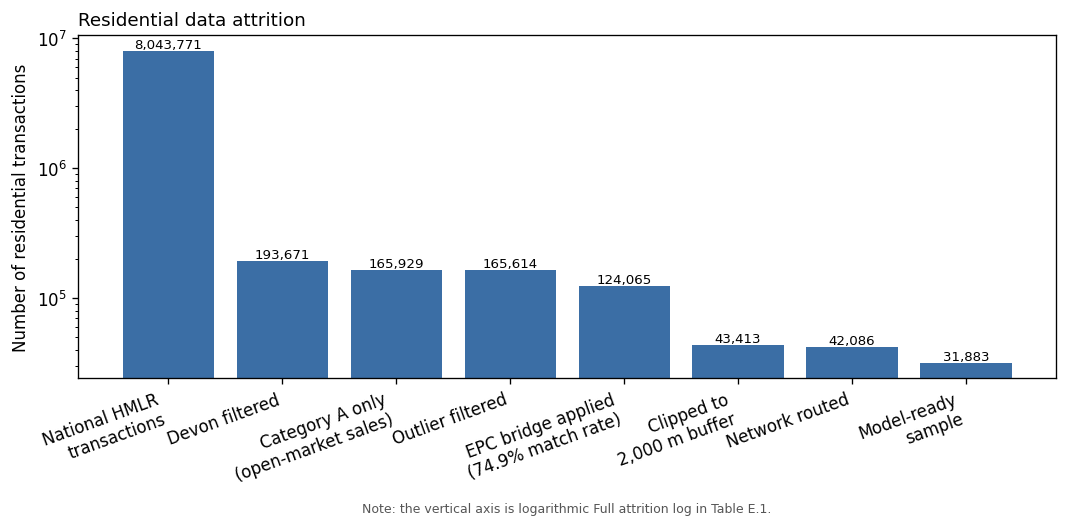

  saved: fig1_residential_attrition.png -> True


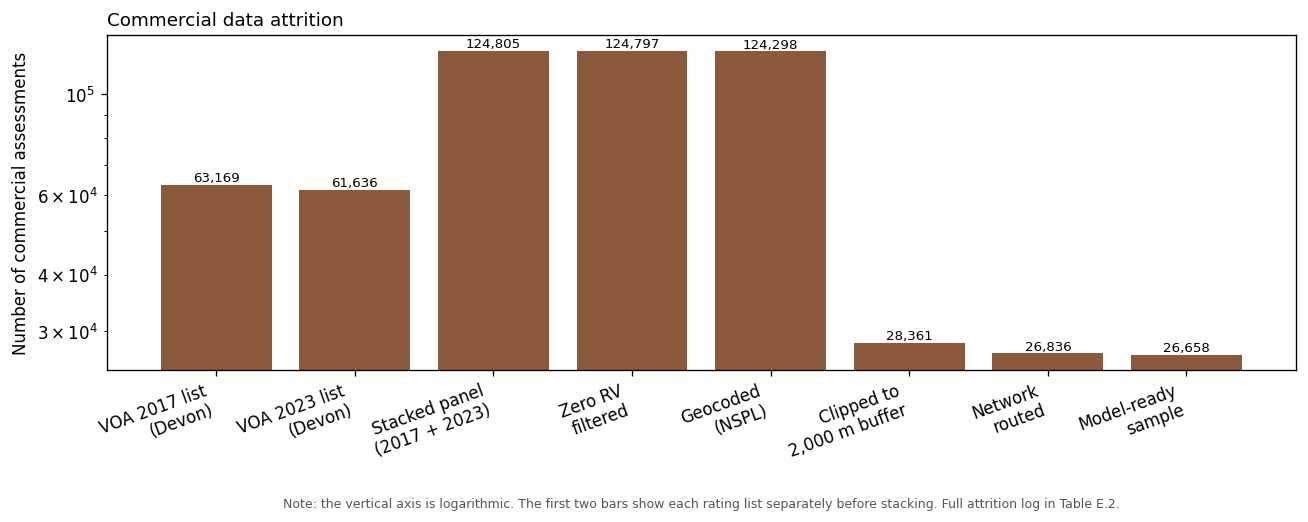

  saved: fig2_commercial_attrition.png -> True


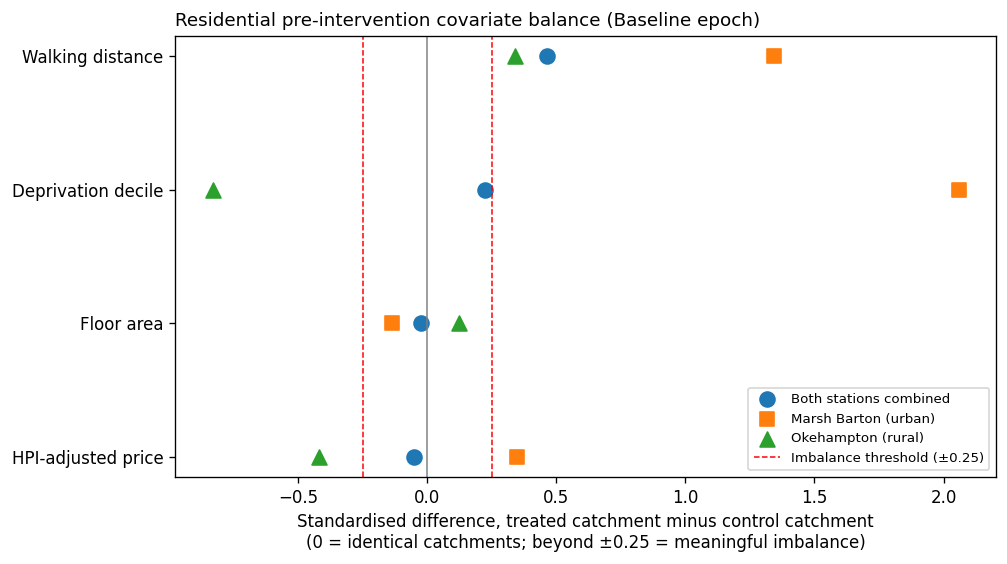

  saved: fig3_residential_balance.png -> True


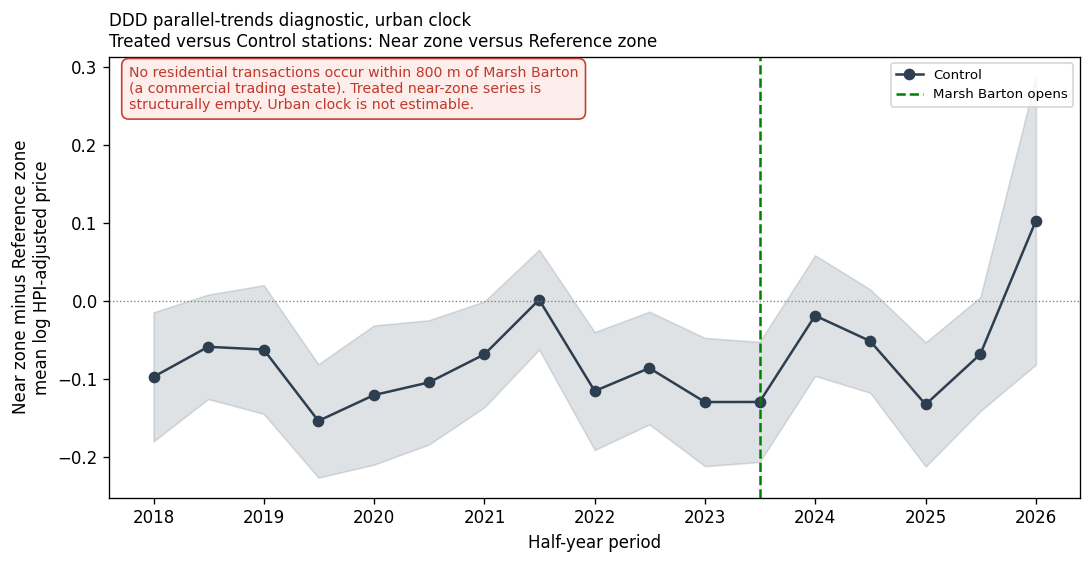

  saved: fig4a_residential_parallel_trends_urban.png -> True


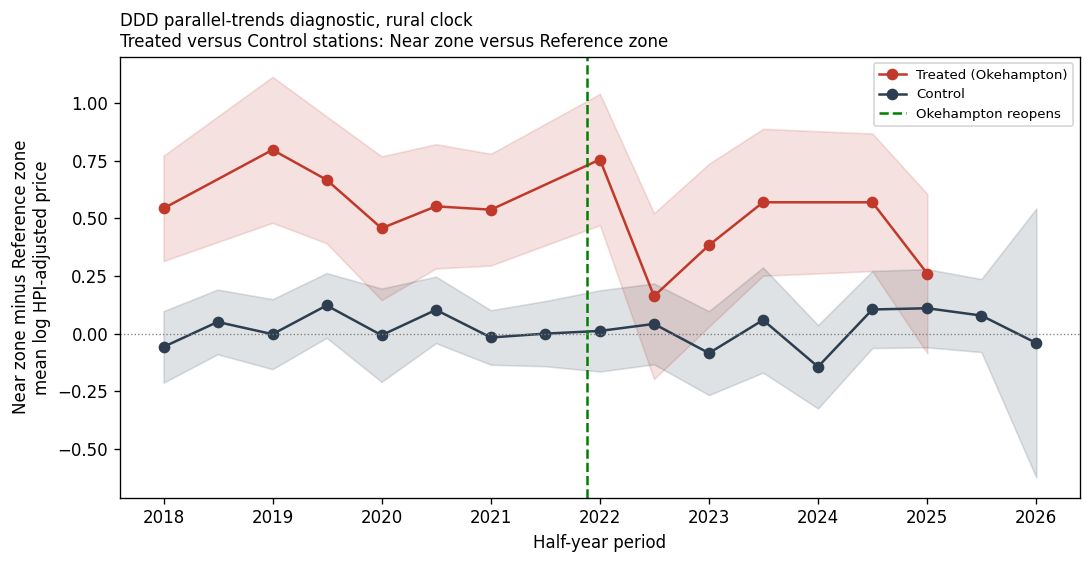

  saved: fig4b_residential_parallel_trends_rural.png -> True


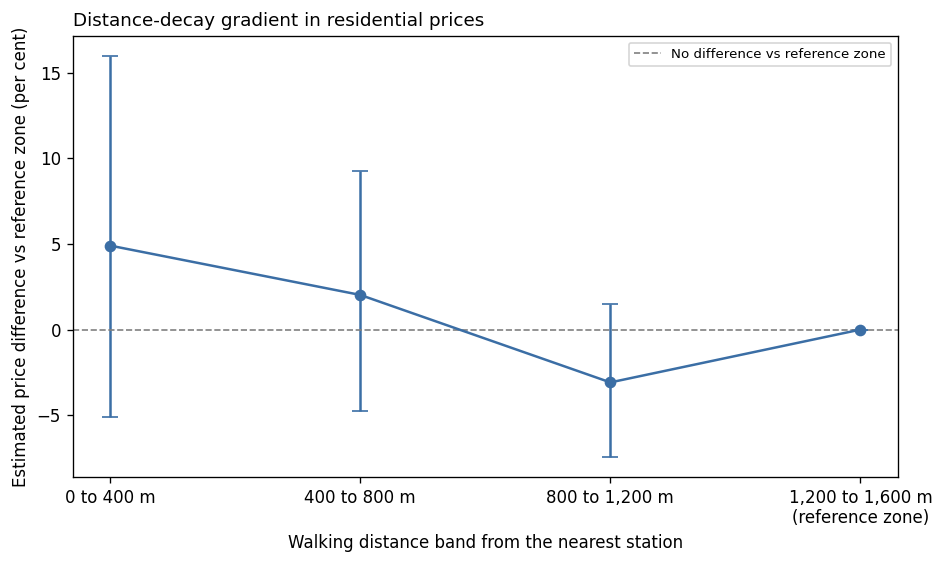

  saved: fig5_residential_decay.png -> True


In [ ]:
# ==============================================================================
# FIGURES (saved to 04_results/figures)
# ==============================================================================
import os, json, traceback
import json
log = json.load(open(os.path.join(BASE_DIR, '05_logs/script_logs/attrition_log.json')))
matplotlib.rcParams.update({'figure.dpi': 120, 'font.size': 10})
os.makedirs(FIG_DIR, exist_ok=True)

COL_TREAT = '#c0392b'
COL_CTRL  = '#2c3e50'

def save_fig(fname):
    path = os.path.join(FIG_DIR, fname)
    plt.savefig(path, bbox_inches='tight'); plt.show()
    print('  saved:', fname, '->', os.path.exists(path))


# FIG 1 (RESIDENTIAL): attrition
try:
    steps = [
        ('National HMLR\ntransactions',              8043771),
        ('Devon filtered',                           193671),
        ('Category A only\n(open-market sales)',     165929),
        ('Outlier filtered',                         165614),
        ('EPC bridge applied\n(74.9% match rate)',          124065),
        ('Clipped to\n2,000 m buffer',              43413),
        ('Network routed',                           42086),
        ('Model-ready\nsample',                      len(res))
    ]
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.bar([s[0] for s in steps], [s[1] for s in steps], color='#3b6ea5')
    for i, s in enumerate(steps):
        ax.text(i, s[1], f"{s[1]:,}", ha='center', va='bottom', fontsize=8)
    ax.set_yscale('log')
    ax.set_ylabel('Number of residential transactions')
    ax.set_title('Residential data attrition', fontsize=11, loc='left')
    plt.xticks(rotation=20, ha='right')
    ax.text(0.5, -0.36,
            'Note: the vertical axis is logarithmic '
            'Full attrition log in Table E.1.',
            transform=ax.transAxes, ha='center', va='top', fontsize=7.5, color='#555')
    plt.tight_layout()
    save_fig('fig1_residential_attrition.png')
except Exception:
    print('FIG 1 FAILED:'); traceback.print_exc()

# FIG 2 (COMMERCIAL): attrition
try:
    csteps = [
        ('VOA 2017 list\n(Devon)',                   63169),
        ('VOA 2023 list\n(Devon)',                   61636),
        ('Stacked panel\n(2017 + 2023)',             124805),
        ('Zero RV\nfiltered',                        124797),
        ('Geocoded\n(NSPL)',                         124298),
        ('Clipped to\n2,000 m buffer',               28361),
        ('Network\nrouted',                          26836),
        ('Model-ready\nsample',                      len(com))
    ]
    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.bar([s[0] for s in csteps], [s[1] for s in csteps], color='#8a5a3b')
    for i, s in enumerate(csteps):
        ax.text(i, s[1], f"{s[1]:,}", ha='center', va='bottom', fontsize=8)
    ax.set_yscale('log')
    ax.set_ylabel('Number of commercial assessments')
    ax.set_title('Commercial data attrition', fontsize=11, loc='left')
    plt.xticks(rotation=20, ha='right')
    ax.text(0.5, -0.38,
            'Note: the vertical axis is logarithmic. The first two bars show each rating list '
            'separately before stacking. Full attrition log in Table E.2.',
            transform=ax.transAxes, ha='center', va='top', fontsize=7.5, color='#555')
    plt.tight_layout()
    save_fig('fig2_commercial_attrition.png')
except Exception:
    print('FIG 2 FAILED:'); traceback.print_exc()

# FIG 3 (RESIDENTIAL): balance
try:
    bal_rows = []
    for label, frame in [('Both stations combined', res),
                          ('Marsh Barton (urban)',   res[res['Group'] == 'Urban']),
                          ('Okehampton (rural)',     res[res['Group'] == 'Rural'])]:
        base = frame[(frame['Epoch'] == 'Baseline') & (frame['In_Catchment'])]
        for col, name in [('Price_Normalised', 'HPI-adjusted price'),
                           ('Total_Floor_Area', 'Floor area'),
                           ('IMD_Decile',       'Deprivation decile'),
                           ('walk_dist_m',      'Walking distance')]:
            t  = base.loc[base['Treated'] == 1, col]
            k  = base.loc[base['Treated'] == 0, col]
            sd = np.sqrt((t.var() + k.var()) / 2)
            bal_rows.append({'group': label, 'variable': name,
                             'std_diff': (t.mean() - k.mean()) / sd if sd > 0 else np.nan})
    bal = pd.DataFrame(bal_rows)
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    markers = {'Both stations combined': 'o', 'Marsh Barton (urban)': 's', 'Okehampton (rural)': '^'}
    for grp in ['Both stations combined', 'Marsh Barton (urban)', 'Okehampton (rural)']:
        sub = bal[bal['group'] == grp]
        ax.scatter(sub['std_diff'], sub['variable'], marker=markers[grp], s=80, label=grp)
    ax.axvline(0,     color='grey', lw=0.9)
    ax.axvline( 0.25, color='red',  ls='--', lw=0.9, label='Imbalance threshold (±0.25)')
    ax.axvline(-0.25, color='red',  ls='--', lw=0.9)
    ax.set_title('Residential pre-intervention covariate balance (Baseline epoch)', fontsize=11, loc='left')
    ax.set_xlabel('Standardised difference, treated catchment minus control catchment\n'
                  '(0 = identical catchments; beyond ±0.25 = meaningful imbalance)')
    ax.legend(fontsize=8)
    plt.tight_layout()
    save_fig('fig3_residential_balance.png')
except Exception:
    print('FIG 3 FAILED:'); traceback.print_exc()


# FIG 4 (RESIDENTIAL): parallel trends
# Plots the near zone vs reference zone price GAP over time for treated and
# control stations. This tests the DDD parallel-trends assumption directly
def _half_start(d):
    return pd.Timestamp(year=d.year, month=(1 if d.month <= 6 else 7), day=1)

def event_plot(group_name, open_date, fname, place_label, action_label):
    # Filter to in-catchment, Near and Ref zones only, for this clock
    g = res[
        (res['Group'] == group_name) &
        res['In_Catchment'] &
        (res['Near'] | res['Ref'])
    ].copy()
    g['half'] = g['Date_of_Transfer'].apply(_half_start)

    fig, ax = plt.subplots(figsize=(9.2, 4.8))
    treat_has_data = False

    for tr, lab, col in [(1, f'Treated ({place_label})', COL_TREAT),
                         (0, 'Control',                   COL_CTRL)]:
        sub = g[g['Treated'] == tr].copy()

        # Aggregate mean, sem, count per half-year and zone
        agg = sub.groupby(['half', 'Near'])['Log_Price'].agg(
            mean='mean', sem='sem', count='count'
        ).reset_index()

        near = agg[agg['Near'] == 1].set_index('half')
        ref  = agg[agg['Near'] == 0].set_index('half')

        # Require at least 3 transactions in both zones for each half-year
        common = near.index.intersection(ref.index)
        valid = [h for h in common
                 if near.loc[h, 'count'] >= 3 and ref.loc[h, 'count'] >= 3]

        if len(valid) == 0:
            continue

        near_v = near.loc[valid]
        ref_v  = ref.loc[valid]

        # Gap = near minus reference mean log price
        gap    = near_v['mean'] - ref_v['mean']

        # Propagated SE of the gap: sqrt(SE_near^2 + SE_ref^2)
        gap_se = np.sqrt(near_v['sem'].fillna(0)**2 + ref_v['sem'].fillna(0)**2)
        gap_lo = gap - 1.96 * gap_se
        gap_hi = gap + 1.96 * gap_se

        if tr == 1:
            treat_has_data = True

        ax.plot(gap.index, gap.values, marker='o', label=lab, color=col)
        ax.fill_between(gap.index, gap_lo, gap_hi, alpha=0.15, color=col)

    ax.axvline(open_date, ls='--', color='green',
               label=f'{place_label} {action_label}')
    ax.axhline(0, ls=':', color='grey', linewidth=0.8)

    if not treat_has_data:
        ax.text(0.02, 0.98,
                f'No residential transactions occur within 800 m of {place_label}\n'
                f'(a commercial trading estate). Treated near-zone series is\n'
                f'structurally empty. Urban clock is not estimable.',
                transform=ax.transAxes, ha='left', va='top', fontsize=8.5,
                color=COL_TREAT,
                bbox=dict(boxstyle='round,pad=0.5', facecolor='#fdecea',
                          edgecolor=COL_TREAT, alpha=0.95))

    ax.set_title(
        f'DDD parallel-trends diagnostic, {group_name.lower()} clock\n'
        f'Treated versus Control stations: Near zone versus Reference zone',
        fontsize=10, loc='left')
    ax.set_ylabel('Near zone minus Reference zone\nmean log HPI-adjusted price')
    ax.set_xlabel('Half-year period')
    ax.legend(fontsize=8, loc='upper right')
    plt.tight_layout()
    save_fig(fname)

try:
    event_plot('Urban', OPENING['Marsh Barton'],
               'fig4a_residential_parallel_trends_urban.png', 'Marsh Barton', 'opens')
    event_plot('Rural', OPENING['Okehampton'],
               'fig4b_residential_parallel_trends_rural.png', 'Okehampton', 'reopens')
except Exception:
    print('FIG 4 FAILED:'); traceback.print_exc()


# FIG 5 (RESIDENTIAL): decay gradient
try:
    order      = ['0-400m', '400-800m', '800-1200m', '1200-1600m']
    band_names = ['0 to 400 m', '400 to 800 m', '800 to 1,200 m',
                  '1,200 to 1,600 m\n(reference zone)']
    dd = decay_df.set_index('band').loc[order].reset_index()
    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.errorbar(band_names, dd['pct'],
                yerr=[dd['pct'] - dd['lo'], dd['hi'] - dd['pct']],
                fmt='o-', capsize=5, color='#3b6ea5')
    ax.axhline(0, color='grey', lw=1.0, ls='--', label='No difference vs reference zone')
    ax.set_title('Distance-decay gradient in residential prices',
                 fontsize=11, loc='left')
    ax.set_ylabel('Estimated price difference vs reference zone (per cent)')
    ax.set_xlabel('Walking distance band from the nearest station')
    ax.legend(fontsize=8)
    plt.tight_layout()
    save_fig('fig5_residential_decay.png')
except Exception:
    print('FIG 5 FAILED:'); traceback.print_exc()


In [ ]:
# ==============================================================================
# EXPORT REGRESSION TABLES TO CSV (for the dissertation tables)
# ==============================================================================
def model_to_df(m, name):
    out = pd.DataFrame({
        'Term':        m.params.index,
        'Coefficient': m.params.values,
        'Std_Error':   m.bse.values,
        'z_Statistic': m.tvalues.values,
        'p_Value':     m.pvalues.values,
        'CI_Lower_95': (m.params - 1.96 * m.bse).round(4).values,
        'CI_Upper_95': (m.params + 1.96 * m.bse).round(4).values,
    })
    out['Model'] = name
    return out

tables = [model_to_df(m_prim, 'Residential_Primary_DiD'),
          model_to_df(m_hed,  'Residential_4band_Hedonic'),
          model_to_df(m_comm, 'Commercial_Anticipation_DiD')]
if m_urban is not None: tables.append(model_to_df(m_urban, 'Residential_Urban_DiD'))
if m_rural is not None: tables.append(model_to_df(m_rural, 'Residential_Rural_DiD'))
all_tab = pd.concat(tables, ignore_index=True)
all_tab.to_csv(os.path.join(TAB_DIR, 'all_regression_results.csv'), index=False)

summary = pd.DataFrame([
    {'Model':            'Residential_Primary_DiD',
     'Term':             'Treated:Near:Post',
     'Coefficient':      m_prim.params[KEY],
     'Clustered_p':      m_prim.pvalues[KEY],
     'Wild_Bootstrap_p': p_wcb,
     'N':                int(m_prim.nobs)},
    {'Model':            'Commercial_Anticipation_DiD',
     'Term':             'Treated:Near:Post',
     'Coefficient':      m_comm.params[KEY],
     'Clustered_p':      m_comm.pvalues[KEY],
     'Wild_Bootstrap_p': p_wcb_c,
     'N':                int(m_comm.nobs)},
])
summary.to_csv(os.path.join(TAB_DIR, 'headline_results.csv'), index=False)
print("Saved regression tables to", TAB_DIR)
print(summary.to_string(index=False))

Saved regression tables to /content/drive/MyDrive/MSc_Dissertation_Project/04_results/tables
                      Model              Term  Coefficient  Clustered_p  Wild_Bootstrap_p     N
    Residential_Primary_DiD Treated:Near:Post    -0.023348     0.686291             0.776  6587
Commercial_Anticipation_DiD Treated:Near:Post    -0.124337     0.048731             0.108 11314


In [ ]:
import pandas as pd, os
BASE_DIR = PROJECT_ROOT
df_test = pd.read_parquet(os.path.join(BASE_DIR, '02_processed_data/03_model_ready/regression_ready_commercial.parquet'))
print(f"Direct read from disk: {len(df_test)} rows")
print(f"Null count: {df_test.isnull().sum().sum()}")

Direct read from disk: 26658 rows
Null count: 0
